### Begin

In [43]:
# env1 3.11.13
import pandas as pd
from pathlib import Path
import requests
import pandas as pd
import numpy as np
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt



exports = Path("loadcurves/exports")

#### Weather

In [79]:
# PUMA COAST
# 2A HOT MOIST climate zone by IECC, see map
puma_coast_GID = pd.read_csv(exports / "tl_2018_48_puma10_COAST.csv")
puma_coast_GID.head()

,STATEFP10,PUMACE10,GEOID10,NAMELSAD10,MTFCC10,FUNCSTAT10,ALAND10,AWATER10,INTPTLAT10,INTPTLON10,Shape_Length,Shape_Area
0,48,4501,4804501,Houston-Galveston Area Council--Montgomery Cou...,G6120,S,1.273119e+09,52320435.0,30.378177,-95.457565,2.390941,0.124389
1,48,4504,4804504,Houston-Galveston Area Council--Montgomery Cou...,G6120,S,3.839967e+08,3209353.0,30.134933,-95.269190,1.139420,0.036250
2,48,4625,4804625,"Harris County (North)--Houston (North), Humble...",G6120,S,1.982250e+08,5920930.0,29.988816,-95.271452,0.743203,0.019083
3,48,4602,4804602,Houston City (East Central)--East of I-45 & In...,G6120,S,6.606648e+07,2105617.0,29.740241,-95.308259,0.339809,0.006358
4,48,4618,4804618,Houston City (Southeast)--West of Pasadena Cit...,G6120,S,5.222547e+07,684618.0,29.679064,-95.288053,0.403428,0.004931


56 PUMA différents, donc globalement 56 comtés différents recensés

In [87]:
puma_coast_GID.PUMACE10.unique()

array([4501, 4504, 4625, 4602, 4618, 4619, 4901, 4902, 4903, 4400, 4701,
       4803, 5000, 4624, 4606, 4620, 4801, 4617, 4802, 4502, 4607, 4601,
       4608, 4603, 4616, 4904, 4632, 5600, 4503, 4637, 4610, 4615, 4634,
       4630, 4629, 4609, 4614, 4623, 4622, 4621, 4702, 5500, 4605, 4905,
       4627, 4626, 4604, 4638, 4635, 4636, 4633, 4628, 4612, 4631, 4611,
       4613])

In [90]:
# 1. Convert columns to strings and add leading zeros (padding)
# STATEFP10 needs 2 digits (e.g., 48)
state_str = puma_coast_GID['STATEFP10'].astype(str).str.zfill(2)

# PUMACE10 needs 5 digits (e.g., 00870)
puma_str = puma_coast_GID['PUMACE10'].astype(str).str.zfill(5)

# 2. Concatenate
gid_series = 'G' + state_str + puma_str

# 3. Convert to list
GID_list = gid_series.tolist()

# Verify
print(GID_list[:5])

['G4804501', 'G4804504', 'G4804625', 'G4804602', 'G4804618']


In [46]:
# in EST time zone, no daylight saving time observed

In [97]:
# 1. Define the base URL
base_url = "https://oedi-data-lake.s3.amazonaws.com/nrel-pds-building-stock/end-use-load-profiles-for-us-building-stock/2025/resstock_amy2017_release_1/weather/state=TX/"

# 2. List of file names to load
file_names = [f"{gid}_2017.csv" for gid in GID_list]

# 3. Load files and add the ID column
data_frames = []

for file_name in file_names:
    full_url = base_url + file_name
    
    # Extract the ID (the "G" part) by splitting at the underscore
    # "G4800870_2018.csv" -> ["G4800870", "2018.csv"] -> "G4800870"
    file_id = file_name.split('_')[0]
    
    print(f"Loading {file_name} (ID: {file_id})...")
    
    try:
        df = pd.read_csv(full_url)
        
        # Add the extracted ID as a new column
        df['location_id'] = file_id
        
        data_frames.append(df)
        
    except Exception as e:
        print(f"Error loading {file_name}: {e}")

# 4. Combine all into a single DataFrame (Optional)
if data_frames:
    all_data_bis = pd.concat(data_frames, ignore_index=True)

Loading G4804501_2017.csv (ID: G4804501)...
Error loading G4804501_2017.csv: HTTP Error 404: Not Found
Loading G4804504_2017.csv (ID: G4804504)...
Error loading G4804504_2017.csv: HTTP Error 404: Not Found
Loading G4804625_2017.csv (ID: G4804625)...
Error loading G4804625_2017.csv: HTTP Error 404: Not Found
Loading G4804602_2017.csv (ID: G4804602)...
Error loading G4804602_2017.csv: HTTP Error 404: Not Found
Loading G4804618_2017.csv (ID: G4804618)...
Error loading G4804618_2017.csv: HTTP Error 404: Not Found
Loading G4804619_2017.csv (ID: G4804619)...
Error loading G4804619_2017.csv: HTTP Error 404: Not Found
Loading G4804901_2017.csv (ID: G4804901)...
Error loading G4804901_2017.csv: HTTP Error 404: Not Found
Loading G4804902_2017.csv (ID: G4804902)...
Error loading G4804902_2017.csv: HTTP Error 404: Not Found
Loading G4804903_2017.csv (ID: G4804903)...
Error loading G4804903_2017.csv: HTTP Error 404: Not Found
Loading G4804400_2017.csv (ID: G4804400)...
Error loading G4804400_2017.c

In [98]:
all_data_bis.location_id.unique()

NameError: name 'all_data_bis' is not defined

In [47]:
# 1. Define the base URL
base_url = "https://oedi-data-lake.s3.amazonaws.com/nrel-pds-building-stock/end-use-load-profiles-for-us-building-stock/2025/resstock_amy2018_release_1/weather/state=TX/"

# 2. List of file names to load
file_names = [f"{gid}_2018.csv" for gid in GID_list]

# 3. Load files and add the ID column
data_frames = []

for file_name in file_names:
    full_url = base_url + file_name
    
    # Extract the ID (the "G" part) by splitting at the underscore
    # "G4800870_2018.csv" -> ["G4800870", "2018.csv"] -> "G4800870"
    file_id = file_name.split('_')[0]
    
    print(f"Loading {file_name} (ID: {file_id})...")
    
    try:
        df = pd.read_csv(full_url)
        
        # Add the extracted ID as a new column
        df['location_id'] = file_id
        
        data_frames.append(df)
        
    except Exception as e:
        print(f"Error loading {file_name}: {e}")

# 4. Combine all into a single DataFrame (Optional)
if data_frames:
    all_data = pd.concat(data_frames, ignore_index=True)

Loading G4804501_2018.csv (ID: G4804501)...
Error loading G4804501_2018.csv: HTTP Error 404: Not Found
Loading G4804504_2018.csv (ID: G4804504)...
Error loading G4804504_2018.csv: HTTP Error 404: Not Found
Loading G4804625_2018.csv (ID: G4804625)...
Error loading G4804625_2018.csv: HTTP Error 404: Not Found
Loading G4804602_2018.csv (ID: G4804602)...
Error loading G4804602_2018.csv: HTTP Error 404: Not Found
Loading G4804618_2018.csv (ID: G4804618)...
Error loading G4804618_2018.csv: HTTP Error 404: Not Found
Loading G4804619_2018.csv (ID: G4804619)...
Error loading G4804619_2018.csv: HTTP Error 404: Not Found
Loading G4804901_2018.csv (ID: G4804901)...
Error loading G4804901_2018.csv: HTTP Error 404: Not Found
Loading G4804902_2018.csv (ID: G4804902)...
Error loading G4804902_2018.csv: HTTP Error 404: Not Found
Loading G4804903_2018.csv (ID: G4804903)...
Error loading G4804903_2018.csv: HTTP Error 404: Not Found
Loading G4804400_2018.csv (ID: G4804400)...
Error loading G4804400_2018.c

In [48]:
all_data.location_id.unique()

<StringArray>
['G4804610', 'G4804630']
Length: 2, dtype: str

In [49]:
weather = all_data.copy()
weather.to_csv(exports / "TX_PUMA_COAST_2018_weather.csv", index=False)

In [50]:
weather.head()

,date_time,Dry Bulb Temperature [°C],Relative Humidity [%],Wind Speed [m/s],Wind Direction [Deg],Global Horizontal Radiation [W/m2],Direct Normal Radiation [W/m2],Diffuse Horizontal Radiation [W/m2],location_id
0,2018-01-01 01:00:00,-7.20,69.04,4.27,43.33,0.0,0.0,0.0,G4804610
1,2018-01-01 02:00:00,-7.20,67.18,5.70,30.00,0.0,0.0,0.0,G4804610
2,2018-01-01 03:00:00,-7.80,61.24,5.70,50.00,0.0,0.0,0.0,G4804610
3,2018-01-01 04:00:00,-8.05,66.95,5.95,50.00,0.0,0.0,0.0,G4804610
4,2018-01-01 05:00:00,-9.40,60.31,6.70,40.00,0.0,0.0,0.0,G4804610


In [91]:
weather.location_id.unique()

<StringArray>
['G4804610', 'G4804630']
Length: 2, dtype: str

#### Load ERCOT

In [51]:
# from https://www.ercot.com/gridinfo/load/load_hist

# most likely in Central Time Zone (CT), needs conversion

ercot_native_2018 = pd.read_excel(exports / "Native_Load_2018.xlsx", sheet_name="Native Load Report")

In [52]:
ercot_native_2018.head()

,HourEnding,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT
0,01/01/2018 01:00,11425.979115,1852.663959,2823.409245,1135.360907,18584.343617,3831.649454,9151.190703,1762.472684,50567.069682
1,01/01/2018 02:00,11408.418023,1850.169452,2809.745403,1136.630855,18524.141392,3988.271046,9144.993712,1754.718094,50617.087977
2,01/01/2018 03:00,11405.198365,1858.269586,2797.802576,1135.930264,18532.056616,4076.086451,9141.036615,1747.919615,50694.300087
3,01/01/2018 04:00,11450.560138,1879.623596,2807.793880,1146.069491,18647.444612,4154.939804,9157.956866,1755.203307,50999.591693
4,01/01/2018 05:00,11631.337459,1876.481320,2822.989206,1154.186967,19002.102222,4247.451523,9214.333628,1774.849690,51723.732017


In [92]:
ercot_native_2018.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   HourEnding  8760 non-null   str    
 1   COAST       8760 non-null   float64
 2   EAST        8760 non-null   float64
 3   FWEST       8760 non-null   float64
 4   NORTH       8760 non-null   float64
 5   NCENT       8760 non-null   float64
 6   SOUTH       8760 non-null   float64
 7   SCENT       8760 non-null   float64
 8   WEST        8760 non-null   float64
 9   ERCOT       8760 non-null   float64
dtypes: float64(9), str(1)
memory usage: 684.5 KB


#### NREL Resstock

In [53]:
# from https://data.openei.org/s3_viewer?bucket=oedi-data-lake&prefix=nrel-pds-building-stock%2Fend-use-load-profiles-for-us-building-stock%2F2025%2Fresstock_amy2018_release_1%2Ftimeseries_aggregates%2Fby_ashrae_iecc_climate_zone_2004%2Fupgrade%3D0%2F&limit=50

# 1. Setup
zone_folder = "2A"  # Folder on S3 (Uppercase)
zone_prefix = "2a"  # Filename prefix (Lowercase)
output_dir = exports

# Create directory (mkdir -p)
output_dir.mkdir(parents=True, exist_ok=True)

In [54]:
# 2. Base URL
base_url = (
    "https://oedi-data-lake.s3.amazonaws.com/"
    "nrel-pds-building-stock/end-use-load-profiles-for-us-building-stock/2025/"
    "resstock_amy2018_release_1/timeseries_aggregates/"
    "by_ashrae_iecc_climate_zone_2004/upgrade=0/"
    f"ashrae_iecc_climate_zone_2004={zone_folder}/"
)

# 3. File List
file_names = [
    f"up00-{zone_prefix}-mobile_home.csv",
    f"up00-{zone_prefix}-multi-family_with_2_-_4_units.csv",
    f"up00-{zone_prefix}-multi-family_with_5plus_units.csv",
    f"up00-{zone_prefix}-single-family_attached.csv",
    f"up00-{zone_prefix}-single-family_detached.csv"
]

# 4. Download Loop
for fname in file_names:
    full_url = base_url + fname
    save_path = output_dir / fname  # Pathlib joins paths with /
    
    print(f"Fetching {fname}...")
    
    try:
        with requests.get(full_url, stream=True) as r:
            r.raise_for_status()
            # Open file using pathlib's open method
            with save_path.open('wb') as f:
                for chunk in r.iter_content(chunk_size=8192):
                    f.write(chunk)
        print(f" -> Saved to {save_path}")
        
    except Exception as e:
        print(f"Error on {fname}: {e}")

Fetching up00-2a-mobile_home.csv...
 -> Saved to loadcurves/exports/up00-2a-mobile_home.csv
Fetching up00-2a-multi-family_with_2_-_4_units.csv...
 -> Saved to loadcurves/exports/up00-2a-multi-family_with_2_-_4_units.csv
Fetching up00-2a-multi-family_with_5plus_units.csv...
 -> Saved to loadcurves/exports/up00-2a-multi-family_with_5plus_units.csv
Fetching up00-2a-single-family_attached.csv...
 -> Saved to loadcurves/exports/up00-2a-single-family_attached.csv
Fetching up00-2a-single-family_detached.csv...
 -> Saved to loadcurves/exports/up00-2a-single-family_detached.csv


In [55]:
# 2. Define the EXACT building types you downloaded
# (This ensures we only look for these specific files)
building_types = [
    "mobile_home",
    "single-family_detached",
    "single-family_attached",
    "multi-family_with_2_-_4_units",
    "multi-family_with_5plus_units"
]

# 3. Create the Dictionary
profiles = {}

for btype in building_types:
    # Reconstruct the exact filename pattern
    fname = f"up00-{zone_prefix}-{btype}.csv"
    file_path = output_dir / fname
    
    print(f"Reading {fname} ...")
    
    # Check if it actually exists before trying to read
    if file_path.exists():
        # Read the file
        df = pd.read_csv(file_path)
        
        # Use .stem to get the key without .csv (e.g., "up00-2a-mobile_home")
        # Or you could just use 'btype' as the key if you prefer cleaner keys
        key = file_path.stem
        profiles[key] = df
        
        print(f" -> Success! Loaded {len(df)} rows into key: '{key}'")
    else:
        print(f" -> WARNING: File not found at {file_path}")

# 4. Access your data
# Example: profiles['up00-2a-single-family_detached']

Reading up00-2a-mobile_home.csv ...
 -> Success! Loaded 35040 rows into key: 'up00-2a-mobile_home'
Reading up00-2a-single-family_detached.csv ...
 -> Success! Loaded 35040 rows into key: 'up00-2a-single-family_detached'
Reading up00-2a-single-family_attached.csv ...
 -> Success! Loaded 35040 rows into key: 'up00-2a-single-family_attached'
Reading up00-2a-multi-family_with_2_-_4_units.csv ...
 -> Success! Loaded 35040 rows into key: 'up00-2a-multi-family_with_2_-_4_units'
Reading up00-2a-multi-family_with_5plus_units.csv ...
 -> Success! Loaded 35040 rows into key: 'up00-2a-multi-family_with_5plus_units'


In [56]:
profiles['up00-2a-single-family_detached'].head(3)

,upgrade,in.ashrae_iecc_climate_zone_2004,in.geometry_building_type_recs,timestamp,models_used,units_represented,out.electricity.ceiling_fan.energy_consumption..kwh,out.electricity.clothes_dryer.energy_consumption..kwh,out.electricity.clothes_washer.energy_consumption..kwh,out.electricity.cooling.energy_consumption..kwh,...,out.emissions.total.lrmer_lowrecosthighngprice_15..co2e_kg,out.emissions.total.lrmer_lowrecosthighngprice_25..co2e_kg,out.emissions.total.lrmer_midcase_15..co2e_kg,out.emissions.total.lrmer_midcase_25..co2e_kg,out.load.cooling.energy_delivered..kbtu,out.load.heating.energy_delivered..kbtu,out.load.heating_heat_pump_backup..kbtu,out.load.hot_water.energy_delivered..kbtu,out.load.hot_water_solar_thermal..kbtu,out.load.hot_water_tank_losses..kbtu
0,0,2A,Single-Family Detached,2018-01-01 00:15:00,38948,9.889040e+06,17633.904,91714.625,4938.8145,143684.95,...,1703908.2,1513191.8,2008558.6,1906760.0,1098609.20,18412566.0,5740.2876,691754.00,839.76870,523758.88
1,0,2A,Single-Family Detached,2018-01-01 00:30:00,38948,9.889040e+06,17699.092,88740.470,5289.8950,80996.80,...,1635508.0,1454369.8,1900864.1,1805880.1,436135.22,17963150.0,6524.4604,605451.90,1030.29540,522389.50
2,0,2A,Single-Family Detached,2018-01-01 00:45:00,38948,9.889040e+06,17774.523,90545.280,4725.0327,75393.94,...,1545491.6,1374665.0,1772291.6,1684334.4,391313.70,16736478.0,7424.0186,534118.06,828.23126,520858.03


In [57]:
def aggregate_to_hourly(df_15min, target_col):
    """
    Aggregates 15-min to Hourly (Hour Ending), removes initialization row,
    and DIVIDES by 'units_represented' to get a per-building average.
    """
    # 1. Set Index
    if 'date_time' in df_15min.columns:
        df_15min = df_15min.set_index('date_time')
    
    # 2. Get the Unit Count (Scalar)
    # We assume the count is constant for the whole file, so we grab the first value.
    if 'units_represented' in df_15min.columns:
        units_count = df_15min['units_represented'].iloc[0]
    else:
        print(f"Warning: 'units_represented' not found. Keeping raw values.")
        units_count = 1.0
        
    # Safety check for zero
    if units_count == 0:
        units_count = 1.0

    # 3. Resample to Hourly SUM
    # We sum the 15-min kWh intervals to get total Hourly kWh
    df_hourly = df_15min[[target_col]].resample('h', label='right', closed='right').sum()
    
    # 4. Clean up: Drop the 00:00:00 initialization row
    if not df_hourly.empty and df_hourly.index[0].hour == 0 and df_hourly.index[0].minute == 0:
        df_hourly = df_hourly.iloc[1:]
        
    # 5. NORMALIZE (The Fix)
    # Convert "Total Load of 5000 homes" -> "Average Load of 1 home"
    df_hourly[target_col] = df_hourly[target_col] / units_count
    
    return df_hourly

In [58]:
hourly_profiles = {}

target_column = 'out.electricity.total.energy_consumption..kwh'

for b_type, df_15 in profiles.items():
    # Ensure index is datetime
    if not isinstance(df_15.index, pd.DatetimeIndex):
        # Create standard index (ResStock 2018 usually starts Jan 1 00:00:00)
        df_15.index = pd.date_range(start='2018-01-01 00:00:00', periods=len(df_15), freq='15min')
    
    # Run the NEW aggregation function
    # Note: We pass the whole df_15 so it can find 'units_represented' inside
    df_hourly = aggregate_to_hourly(df_15, target_column)
    
    # Store it
    hourly_profiles[b_type] = df_hourly

print("Aggregation and Normalization Complete.")
print(f"Sample Value (First Hour, First Profile): {next(iter(hourly_profiles.values())).iloc[0,0]:.4f} kWh")

Aggregation and Normalization Complete.
Sample Value (First Hour, First Profile): 1.6859 kWh


#### ML models for each building type

In [59]:
# --- 1. PREPARE WEATHER DATA (X) ---

# Select just one location (since they are identical)
location_id = 'G4804610'
weather_clean = weather[weather['location_id'] == location_id].copy()

# Convert timestamp and sort
weather_clean['date_time'] = pd.to_datetime(weather_clean['date_time'])
weather_clean = weather_clean.sort_values('date_time').reset_index(drop=True)

# Feature Engineering: Add Time Features
# These are critical because people behave differently at 2 AM vs 2 PM, and on Sundays vs Mondays.
weather_clean['hour'] = weather_clean['date_time'].dt.hour
weather_clean['month'] = weather_clean['date_time'].dt.month
weather_clean['day_of_week'] = weather_clean['date_time'].dt.dayofweek  # 0=Monday, 6=Sunday

# Define Feature Columns
feature_cols = [
    'Dry Bulb Temperature [°C]', 
    'Relative Humidity [%]',
    'Wind Speed [m/s]', 
    'Global Horizontal Radiation [W/m2]', 
    'hour', 
    'month', 
    'day_of_week'
]

X = weather_clean[feature_cols]

print(f"Feature Matrix Shape: {X.shape}")
print(f"Features used: {feature_cols}")
print("-" * 30)

Feature Matrix Shape: (8760, 7)
Features used: ['Dry Bulb Temperature [°C]', 'Relative Humidity [%]', 'Wind Speed [m/s]', 'Global Horizontal Radiation [W/m2]', 'hour', 'month', 'day_of_week']
------------------------------


In [60]:
# --- 1. SETUP DIRECTORIES ---
# Create folders if they don't exist
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

metrics_dir = Path("metrics")
metrics_dir.mkdir(exist_ok=True)

print(f"Directories ready: '{models_dir}' and '{metrics_dir}'")

# --- 2. TRAIN LOOP ---

target_col = 'out.electricity.total.energy_consumption..kwh'
models = {}
results_list = []  # List to collect rows for the final CSV

print("Training Random Forest models using Hourly Profiles...")

for b_type, df_hourly in hourly_profiles.items():
    print(f"\nProcessing: {b_type}")
    
    # -- Data Prep --
    y = df_hourly[target_col].values
    
    if len(X) != len(y):
        print(f"!! Mismatch Error: Weather (X) has {len(X)} rows, Profile (y) has {len(y)} rows.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # -- Training --
    rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    # -- Evaluation --
    preds = rf.predict(X_test)
    score = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    print(f" -> Done. R^2 Score: {score:.4f} | RMSE: {rmse:.4f} kWh")
    
    # -- SAVE MODEL --
    # Sanitize filename (replace spaces or special chars if any)
    safe_name = b_type.replace(" ", "_").replace("/", "-")
    model_path = models_dir / f"rf_model_{safe_name}.joblib"
    
    joblib.dump(rf, model_path)
    print(f"    Saved model to: {model_path}")
    
    # -- COLLECT METRICS --
    # Store in memory to create the CSV at the end
    models[b_type] = rf
    results_list.append({
        'Building_Type': b_type,
        'R2_Score': score,
        'RMSE_kWh': rmse,
        'Model_Path': str(model_path)
    })

# --- 3. SAVE METRICS CSV ---
metrics_df = pd.DataFrame(results_list)
metrics_path = metrics_dir / "training_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\n" + "="*30)
print(f"All operations complete.")
print(f"Metrics saved to: {metrics_path}")

Directories ready: 'models' and 'metrics'
Training Random Forest models using Hourly Profiles...

Processing: up00-2a-mobile_home
 -> Done. R^2 Score: 0.8491 | RMSE: 0.2014 kWh
    Saved model to: models/rf_model_up00-2a-mobile_home.joblib

Processing: up00-2a-single-family_detached
 -> Done. R^2 Score: 0.9073 | RMSE: 0.2574 kWh
    Saved model to: models/rf_model_up00-2a-single-family_detached.joblib

Processing: up00-2a-single-family_attached
 -> Done. R^2 Score: 0.9058 | RMSE: 0.1321 kWh
    Saved model to: models/rf_model_up00-2a-single-family_attached.joblib

Processing: up00-2a-multi-family_with_2_-_4_units
 -> Done. R^2 Score: 0.9066 | RMSE: 0.1019 kWh
    Saved model to: models/rf_model_up00-2a-multi-family_with_2_-_4_units.joblib

Processing: up00-2a-multi-family_with_5plus_units
 -> Done. R^2 Score: 0.9487 | RMSE: 0.0538 kWh
    Saved model to: models/rf_model_up00-2a-multi-family_with_5plus_units.joblib

All operations complete.
Metrics saved to: metrics/training_metrics.csv

#### Estimate number of residential buildings for each bus using census B25024

In [61]:
# --- INPUTS ---
state_fips = "48"  # Texas (Change to "06" for CA, "36" for NY, etc.)

In [62]:
import os
# --- EXECUTION ---
# 1. URL construction
# We ask for: NAME (so we can filter by text), and the Group B25024
base_url = "https://api.census.gov/data/2019/acs/acs5"
def _get_census_api_key():
    key = os.environ.get("CENSUS_API_KEY", "").strip()
    if key:
        return key
    key_file = Path("census_api_key.txt")
    if key_file.exists():
        return key_file.read_text().strip()
    return ""

census_api_key = _get_census_api_key()

params = {
    "get": "NAME,group(B25024)",
    "for": "tract:*",
    "in": f"state:{state_fips}",
    "key": census_api_key,
}

if not params["key"]:
    print("WARNING: no Census API key found. Get a free key at https://api.census.gov/data/key_signup.html "
          "and save it (just the key, no quotes) into a file named census_api_key.txt at the repo root.")

print(f"Fetching all tracts for State FIPS {state_fips}...")

# 2. Request
r = requests.get(base_url, params=params)

if r.status_code == 200:
    data = r.json()
    
    # 3. Convert to DataFrame
    df = pd.DataFrame(data[1:], columns=data[0])
    
    # 4. Filter Columns (Keep 'NAME', Geography IDs, and Estimates 'E')
    # We drop 'M' (Margin of Error) and 'EA' (Annotation) columns to keep it clean
    cols_to_keep = ["NAME", "state", "county", "tract"] + \
                   [c for c in df.columns if c.endswith("E") and "B25024" in c]
    
    df = df[cols_to_keep]
    
    # Clean up column names (optional, removes the 'E' suffix for readability?)
    # For now, we leave them as B25024_001E for mapping consistency
    
    # 5. Save the Master File
    output_path = exports/f"census_b25024_state_{state_fips}_tracts.csv"
    df.to_csv(output_path, index=False)
    
    print(f"Success! Downloaded {len(df)} tracts.")
    print(f"Saved to {output_path}")
    
else:
    print(f"Error: {r.status_code}")
    print(r.text)

Fetching all tracts for State FIPS 48...
Success! Downloaded 5265 tracts.
Saved to loadcurves/exports/census_b25024_state_48_tracts.csv


In [63]:
census_b25024 = pd.read_csv(exports/f"census_b25024_state_{state_fips}_tracts.csv")
# vars at https://api.census.gov/data/2019/acs/acs1/variables.html
census_b25024.head(3)

,NAME,NAME.1,state,county,tract,B25024_001E,B25024_002E,B25024_003E,B25024_004E,B25024_005E,B25024_006E,B25024_007E,B25024_008E,B25024_009E,B25024_010E,B25024_011E
0,"Census Tract 133.05, Cameron County, Texas","Census Tract 133.05, Cameron County, Texas",48,61,13305,1472,1182,51,111,48,0,42,0,0,38,0
1,"Census Tract 133.09, Cameron County, Texas","Census Tract 133.09, Cameron County, Texas",48,61,13309,719,653,3,14,15,24,0,0,0,10,0
2,"Census Tract 134.02, Cameron County, Texas","Census Tract 134.02, Cameron County, Texas",48,61,13402,623,485,30,37,63,0,0,3,0,5,0


In [64]:
tract_to_bus_mapping = pd.read_csv(exports / "tract_to_bus_mapping.csv")
tract_to_bus_mapping.head(3)

,Join_Count,TARGET_FID,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,...,Nom_kV,Sub_Num,Substation_Latitude,Substation_Longitude,Load_Mvar,Load_MW,Gen_MW,Gen_Mvar,Shape_Length,Shape_Area
0,1,1,48,167,721201,48167721201,7212.01,Census Tract 7212.01,G5020,S,...,115.0,957,29.500690,-95.081950,60.843,214.74,NaN,NaN,0.190922,0.001462
1,1,2,48,167,722001,48167722001,7220.01,Census Tract 7220.01,G5020,S,...,115.0,999,29.378097,-94.932773,40.605,92.96,NaN,NaN,0.222891,0.000810
2,1,3,48,167,726200,48167726200,7262.00,Census Tract 7262,G5020,S,...,115.0,999,29.378097,-94.932773,40.605,92.96,NaN,NaN,0.553209,0.003821


In [65]:
# 1. Raw Census Definitions (Table B25024)
census_labels = {
    "B25024_001E": "Total",
    "B25024_002E": "1-unit, detached",
    "B25024_003E": "1-unit, attached",
    "B25024_004E": "2 units",
    "B25024_005E": "3 or 4 units",
    "B25024_006E": "5 to 9 units",
    "B25024_007E": "10 to 19 units",
    "B25024_008E": "20 to 49 units",
    "B25024_009E": "50 or more units",
    "B25024_010E": "Mobile home",
    "B25024_011E": "Boat, RV, van, etc."
}

# 2. Mapping Census Vars to NREL Building Types
# Use this to sum the columns correctly for your load profile
nrel_mapping = {
    # Direct mappings
    "single-family_detached": ["B25024_002E"],
    "single-family_attached": ["B25024_003E"],
    "mobile_home":            ["B25024_010E"],
    
    # Aggregations needed for Multi-Family
    "multi-family_with_2_-_4_units": [
        "B25024_004E",  # 2 units
        "B25024_005E"   # 3-4 units
    ],
    "multi-family_with_5plus_units": [
        "B25024_006E",  # 5-9
        "B25024_007E",  # 10-19
        "B25024_008E",  # 20-49
        "B25024_009E"   # 50+
    ]
}

In [66]:
# --- CLEANING (Standardize IDs) ---
# Ensure IDs are strings with leading zeros to match perfectly
tract_to_bus_mapping['STATEFP'] = tract_to_bus_mapping['STATEFP'].astype(str).str.zfill(2)
tract_to_bus_mapping['COUNTYFP'] = tract_to_bus_mapping['COUNTYFP'].astype(str).str.zfill(3)
tract_to_bus_mapping['TRACTCE'] = tract_to_bus_mapping['TRACTCE'].astype(str).str.zfill(6)

census_b25024['state'] = census_b25024['state'].astype(str).str.zfill(2)
census_b25024['county'] = census_b25024['county'].astype(str).str.zfill(3)
census_b25024['tract'] = census_b25024['tract'].astype(str).str.zfill(6)

# Ensure Census counts are numbers
census_cols = [c for c in census_b25024.columns if c.startswith('B25024')]
for col in census_cols:
    census_b25024[col] = pd.to_numeric(census_b25024[col], errors='coerce').fillna(0)

# --- MERGE ---
# Join the Census data to your Bus-Tract map
merged = pd.merge(
    tract_to_bus_mapping, 
    census_b25024,
    left_on=['STATEFP', 'COUNTYFP', 'TRACTCE'],
    right_on=['state', 'county', 'tract'],
    how='left'
)

# --- CALCULATE NREL COLUMNS (Per Row) ---
# First, map the raw Census columns to your 5 NREL types for every row
merged['single-family_detached'] = merged['B25024_002E']
merged['single-family_attached'] = merged['B25024_003E']
merged['mobile_home']            = merged['B25024_010E']

merged['multi-family_with_2_-_4_units'] = (
    merged['B25024_004E'] + merged['B25024_005E']
)

merged['multi-family_with_5plus_units'] = (
    merged['B25024_006E'] + merged['B25024_007E'] + 
    merged['B25024_008E'] + merged['B25024_009E']
)

# --- AGGREGATE BY BUS ---
# Since one bus = many tracts, we group by Bus_Number and SUM the building counts
group_cols = [
    'single-family_detached',
    'single-family_attached',
    'multi-family_with_2_-_4_units',
    'multi-family_with_5plus_units',
    'mobile_home'
]

final_bus_counts = merged.groupby('Bus_Number')[group_cols].sum().reset_index()

# Optional: Round if you want integers
final_bus_counts[group_cols] = final_bus_counts[group_cols].round(0)

In [67]:
final_bus_counts.head(3)

,Bus_Number,single-family_detached,single-family_attached,multi-family_with_2_-_4_units,multi-family_with_5plus_units,mobile_home
0,7001,3438,44,154,689,798
1,7004,8390,140,783,2714,261
2,7010,2522,51,502,383,698


In [68]:
final_bus_counts.to_csv(exports / "final_bus_building_counts.csv", index=False)

#### Multiply N buildings by load profiles

In [69]:
# --- 1. SETUP & LOAD ---
models_dir = Path("models")

# The list of building types (matches your NREL/Census columns)
building_types = [
    "mobile_home",
    "single-family_detached",
    "single-family_attached",
    "multi-family_with_2_-_4_units",
    "multi-family_with_5plus_units"
]

# Ensure we use the exact same features as training
feature_cols = [
    'Dry Bulb Temperature [°C]', 
    'Relative Humidity [%]',
    'Wind Speed [m/s]', 
    'Global Horizontal Radiation [W/m2]', 
    'hour', 'month', 'day_of_week'
]
X_predict = weather_clean[feature_cols]

# --- 2. GENERATE BASE PROFILES (Unit Load) ---
print("Generating base unit profiles for each building type...")
base_profiles_dict = {}

# Define the NREL prefix seen in your files
file_prefix = "up00-2a"

for b_type in building_types:
    # Construct filename: rf_model_up00-2a-mobile_home.joblib
    # We maintain the safe naming (spaces to underscores)
    safe_name = b_type.replace(" ", "_").replace("/", "-")
    
    filename = f"rf_model_{file_prefix}-{safe_name}.joblib"
    model_path = models_dir / filename
    
    if model_path.exists():
        model = joblib.load(model_path)
        
        # Predict 8760 profile for 1 unit
        base_profiles_dict[b_type] = model.predict(X_predict)
    else:
        print(f"!! Error: Model file not found: {filename}")

# Convert to DataFrame (Rows: Time, Cols: Building Types)
base_profiles_df = pd.DataFrame(base_profiles_dict, index=weather_clean['date_time'])

print("Base profiles generated. Shape:", base_profiles_df.shape)

# --- 3. CALCULATE BUS PROFILES (Matrix Multiplication) ---
# (8760 Time x 5 Types) . (5 Types x N Buses) = (8760 Time x N Buses)

# Ensure columns align perfectly
counts_matrix = final_bus_counts.set_index('Bus_Number')[base_profiles_df.columns]
counts_matrix = counts_matrix.fillna(0)

print(f"Counts Matrix Shape: {counts_matrix.shape} (Buses x Types)")

# The Dot Product
bus_profiles_df = base_profiles_df.dot(counts_matrix.T)

# --- 4. SAVE ---
print("\nCalculation Complete!")
print(f"Final Grid Profile Shape: {bus_profiles_df.shape}")

output_path = exports/"final_bus_load_profiles_8760.csv"
bus_profiles_df.to_csv(output_path)
print(f"Saved to {output_path}")

Generating base unit profiles for each building type...
Base profiles generated. Shape: (8760, 5)
Counts Matrix Shape: (200, 5) (Buses x Types)

Calculation Complete!
Final Grid Profile Shape: (8760, 200)
Saved to loadcurves/exports/final_bus_load_profiles_8760.csv


In [70]:
bus_profiles_df.head(3)

Bus_Number,7001,7004,7010,7011,7012,7013,7014,7016,7017,7020,...,7413,7417,7418,7421,7424,7425,7426,7427,7430,7431
date_time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 01:00:00,13894.248449,30996.049441,10998.484572,11271.495935,29146.404919,61197.447526,42202.828513,56871.309658,43370.116661,14193.428489,...,15005.530012,7944.850986,25013.278779,7791.127677,27067.532928,61051.865870,11609.858347,40319.118328,27504.172162,46879.669482
2018-01-01 02:00:00,12674.439088,28048.082879,10068.159744,10531.380023,26251.554856,55376.694800,38260.711814,51616.675228,39388.184470,12956.579848,...,13642.106191,7148.181226,22527.076409,7028.035957,24793.593193,55287.646422,10547.813929,36704.042128,24867.957906,42350.519968
2018-01-01 03:00:00,12982.550936,28778.143828,10308.715408,10737.581500,26953.005114,56797.405950,39226.968973,52914.133246,40375.584309,13268.773589,...,13984.216134,7341.093449,23121.023053,7214.056455,25379.690597,56714.307300,10811.929207,37620.497029,25515.596638,43443.042153


#### Plot

Loading ERCOT Excel file from: loadcurves/exports/Native_Load_2018.xlsx
Conversion Successful.
Timezone: datetime64[us, Etc/GMT+5]


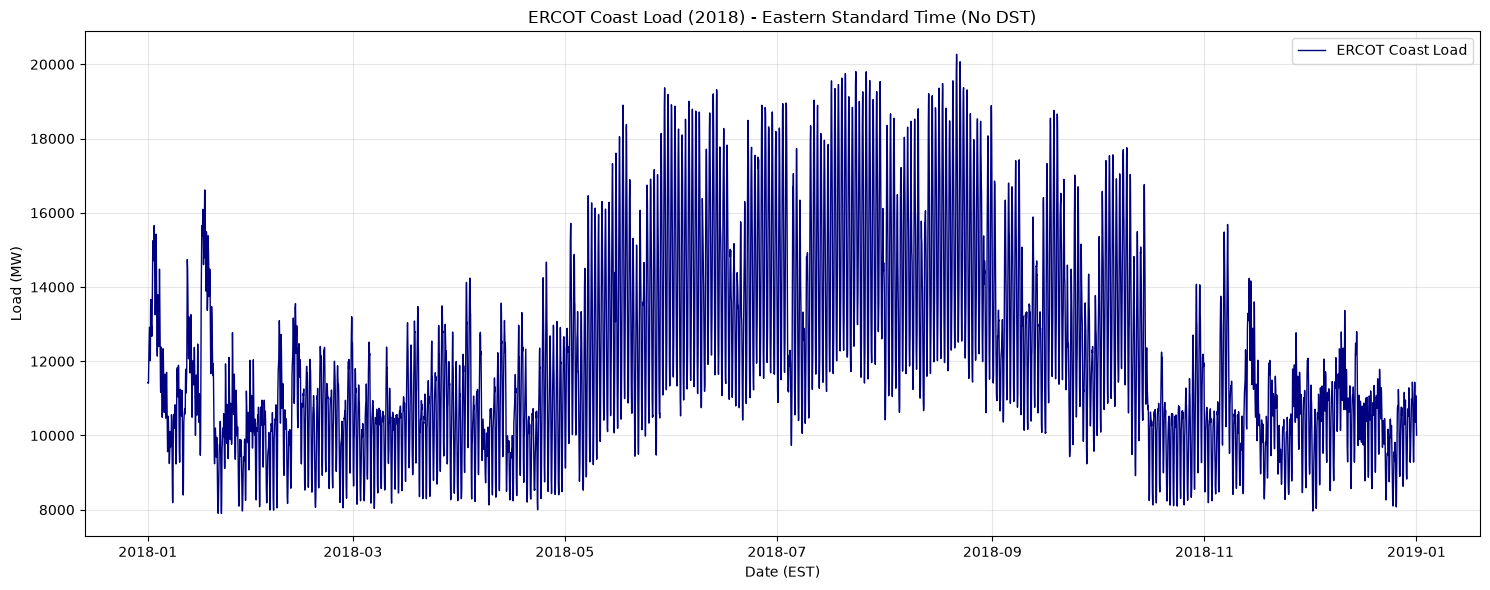

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --- 1. LOAD ERCOT DATA ---
file_path = exports / "Native_Load_2018.xlsx"
print(f"Loading ERCOT Excel file from: {file_path}")

ercot_df = pd.read_excel(file_path, sheet_name="Native Load Report")

# --- 2. PRECISE PARSING ---

# Ensure column is string
ercot_df['HourEnding'] = ercot_df['HourEnding'].astype(str)

# A. Extract DST Flag (The "Truth" Source)
# Create a boolean array: True = DST, False = Standard
is_dst_mask = ercot_df['HourEnding'].str.contains(' DST', regex=False)

# B. Clean the String 
# Remove " DST" so pandas can parse the date
ercot_df['HourEnding'] = ercot_df['HourEnding'].str.replace(' DST', '', regex=False)

# C. Handle "24:00"
# Identify rows that are 24:00
mask_24 = ercot_df['HourEnding'].str.contains('24:00')
# Replace with 00:00 temporarily
ercot_df['HourEnding'] = ercot_df['HourEnding'].str.replace('24:00', '00:00')

# D. Convert to Naive Datetime (Wall Clock Time)
naive_timestamps = pd.to_datetime(ercot_df['HourEnding'])

# E. Fix the "24:00" Date Shift (Add 1 Day)
naive_timestamps.loc[mask_24] += pd.Timedelta(days=1)

# --- 3. TIMEZONE LOCALIZATION ---

# We pass the boolean mask to 'ambiguous'. 
# This tells pandas: "For every row, use this specific True/False value to decide if it is DST."
ercot_df['date_time'] = naive_timestamps.dt.tz_localize(
    'US/Central', 
    ambiguous=is_dst_mask, 
    nonexistent='shift_forward'
)

# Set the clean index
ercot_df = ercot_df.set_index('date_time')

# --- 4. CONVERT TO EST (No DST) ---
# Convert to 'Etc/GMT+5' (Fixed UTC-5, which is EST year-round)
ercot_df_est = ercot_df.tz_convert('Etc/GMT+5')

print("Conversion Successful.")
print(f"Timezone: {ercot_df_est.index.dtype}")

# --- 5. PLOT ---
plt.figure(figsize=(15, 6))

plt.plot(ercot_df_est.index, ercot_df_est['COAST'], 
         color='navy', linewidth=1, label='ERCOT Coast Load')

plt.title("ERCOT Coast Load (2018) - Eastern Standard Time (No DST)")
plt.xlabel("Date (EST)")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

Aggregating estimated loads...
Peak Estimated Load: 9628.22 MW
Minimum Estimated Load: 1574.64 MW


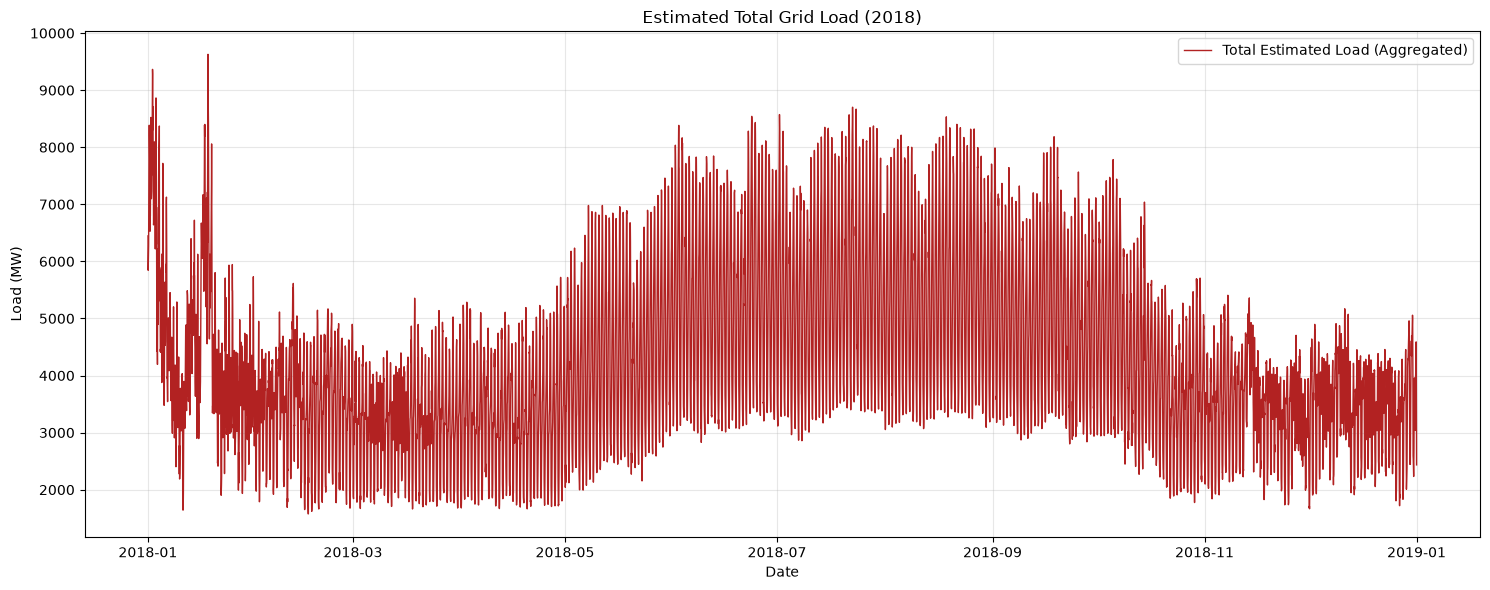

In [72]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 1. PREPARE DATA ---
# Assuming 'bus_profiles_df' is already in memory from the generation step.
# If not, uncomment the line below to load it:
# bus_profiles_df = pd.read_csv("final_bus_load_profiles_8760.csv", index_col=0, parse_dates=True)

print("Aggregating estimated loads...")

# Sum all buses (Columns) to get Total Grid Load
# Units: The raw data is in kWh (which is kW for 1-hour steps).
# We divide by 1,000 to convert to Megawatts (MW).
total_est_load_mw = bus_profiles_df.sum(axis=1) / 1000
print(f"Peak Estimated Load: {total_est_load_mw.max():.2f} MW")
print(f"Minimum Estimated Load: {total_est_load_mw.min():.2f} MW")

# --- 2. PLOT ---
plt.figure(figsize=(15, 6))

plt.plot(total_est_load_mw.index, total_est_load_mw, 
         color='firebrick', linewidth=1, label='Total Estimated Load (Aggregated)')

plt.title("Estimated Total Grid Load (2018)")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

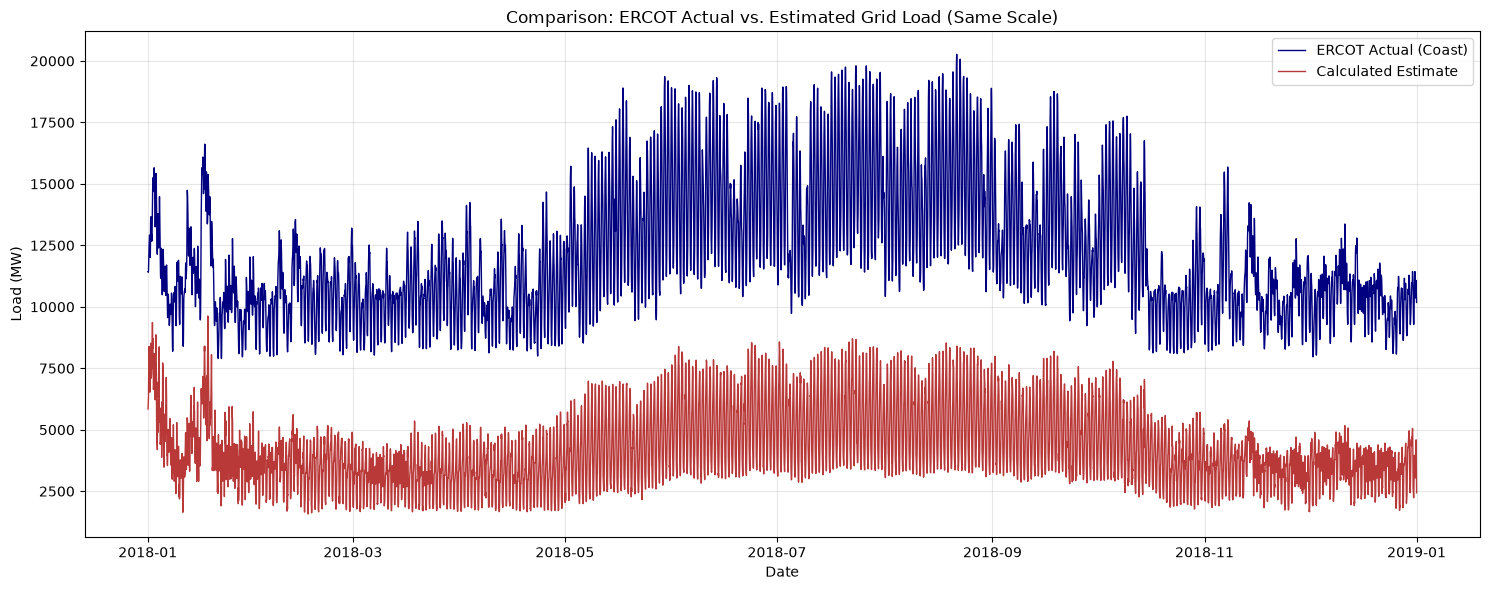

Peak Actual:    20269.85 MW
Peak Estimated: 9628.22 MW


In [73]:
import matplotlib.pyplot as plt

# --- PREPARE DATA ---
# 1. Align Timezones
# We assume 'total_est_load_mw' is Naive (Standard Time) and 'ercot_df_est' is TZ-aware.
# We strip the timezone from ERCOT to allow plotting on the same axis.
ercot_plot_data = ercot_df_est['COAST'].copy()
ercot_plot_data.index = ercot_plot_data.index.tz_localize(None)

# 2. Slice to Common Timeframe
# This ensures we don't have a huge empty gap if the dates don't perfectly overlap
common_start = max(ercot_plot_data.index.min(), total_est_load_mw.index.min())
common_end = min(ercot_plot_data.index.max(), total_est_load_mw.index.max())

y_actual = ercot_plot_data.loc[common_start:common_end]
y_est = total_est_load_mw.loc[common_start:common_end]

# --- PLOT (SINGLE AXIS) ---
plt.figure(figsize=(15, 6))

# Plot 1: ERCOT Actual
plt.plot(y_actual.index, y_actual, 
         color='navy', linewidth=1, label='ERCOT Actual (Coast)')

# Plot 2: Estimated Load
plt.plot(y_est.index, y_est, 
         color='firebrick', linewidth=1, alpha=0.9, label='Calculated Estimate')

# Formatting
plt.title("Comparison: ERCOT Actual vs. Estimated Grid Load (Same Scale)")
plt.xlabel("Date")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# --- Optional: Print Stats ---
print(f"Peak Actual:    {y_actual.max():.2f} MW")
print(f"Peak Estimated: {y_est.max():.2f} MW")

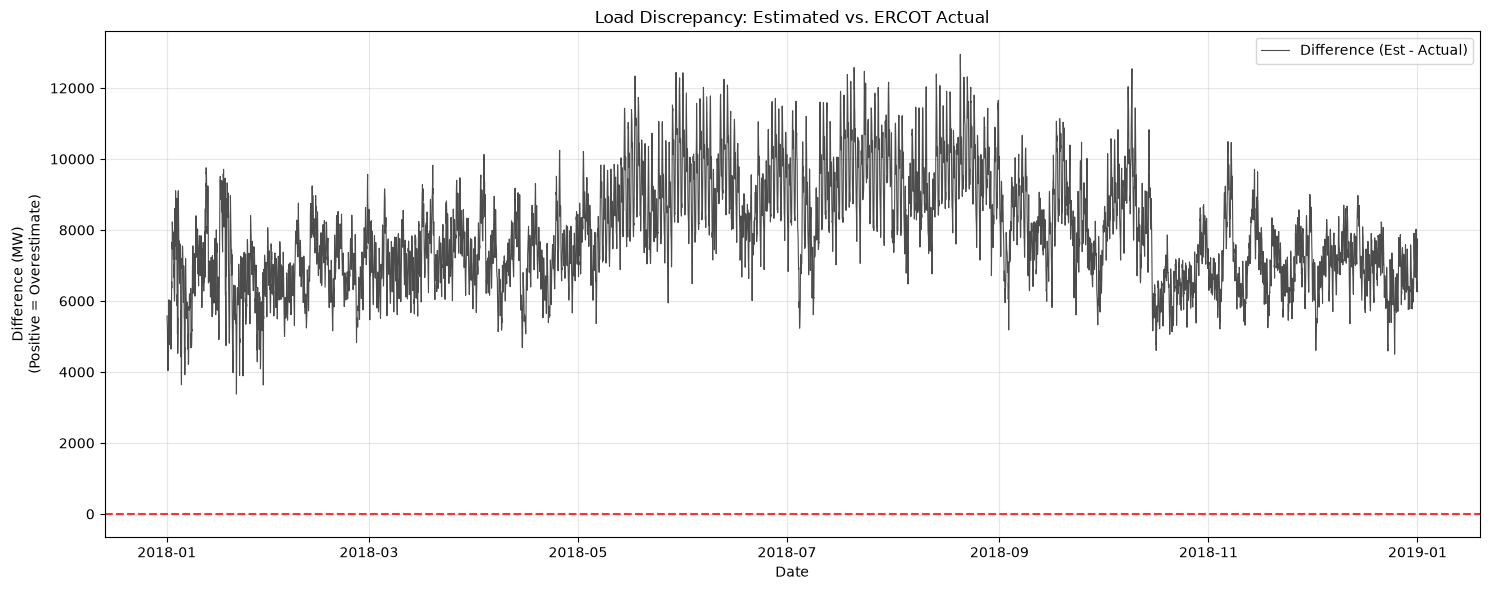

Max Overestimate:  12949.41 MW
Max Underestimate: 3377.60 MW
Mean Error:        7906.61 MW


In [74]:
import matplotlib.pyplot as plt

# --- 1. CALCULATE DIFFERENCE ---
# Difference = Estimated - Actual
# Positive value means your model is HIGHER than actuals
# Negative value means your model is LOWER than actuals
load_difference = y_actual - y_est

# --- 2. PLOT DIFFERENCE ---
plt.figure(figsize=(15, 6))

# Plot the main difference line
plt.plot(load_difference.index, load_difference, 
         color='black', linewidth=0.8, alpha=0.7, label='Difference (Est - Actual)')

# Add a horizontal line at zero for reference
plt.axhline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8)

# Formatting
plt.title("Load Discrepancy: Estimated vs. ERCOT Actual")
plt.xlabel("Date")
plt.ylabel("Difference (MW)\n(Positive = Overestimate)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

# --- 3. PRINT STATS ---
print(f"Max Overestimate:  {load_difference.max():.2f} MW")
print(f"Max Underestimate: {load_difference.min():.2f} MW")
print(f"Mean Error:        {load_difference.mean():.2f} MW")

------------------------------
Overall Shape Correlation: 0.8733
------------------------------


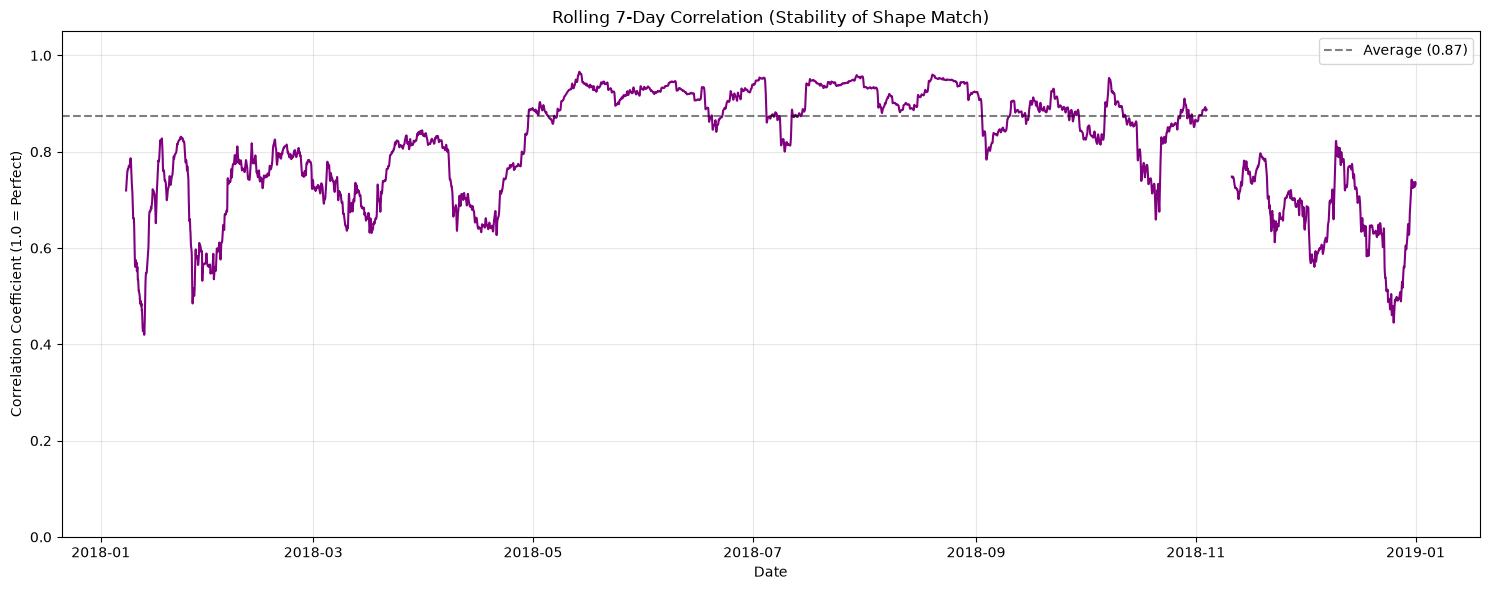

In [75]:
import matplotlib.pyplot as plt
import pandas as pd

# --- 1. OVERALL CORRELATION ---
# Calculate Pearson Correlation
overall_corr = y_est.corr(y_actual)

print("-" * 30)
print(f"Overall Shape Correlation: {overall_corr:.4f}")
print("-" * 30)

# --- 2. ROLLING CORRELATION (Stability Check) ---
# We calculate correlation over a moving window (e.g., 7 days)
# to see if the model works better in some seasons than others.
window_size = 24 * 7  # 7 Days (Hourly data)

rolling_corr = y_est.rolling(window=window_size).corr(y_actual)

plt.figure(figsize=(15, 6))
plt.plot(rolling_corr.index, rolling_corr, color='purple', linewidth=1.5)

plt.axhline(overall_corr, color='black', linestyle='--', alpha=0.5, label=f'Average ({overall_corr:.2f})')
plt.title(f"Rolling 7-Day Correlation (Stability of Shape Match)")
plt.ylabel("Correlation Coefficient (1.0 = Perfect)")
plt.xlabel("Date")
plt.legend()
plt.ylim(0, 1.05) # Focus on positive correlation
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [76]:
import pandas as pd

# --- 1. DEFINE ASSUMPTIONS (People per Housing Unit) ---
# Based on typical US Census averages
occupancy_assumptions = {
    "mobile_home": 2.3,
    "single-family_detached": 2.7,
    "single-family_attached": 2.5,
    "multi-family_with_2_-_4_units": 2.2,
    "multi-family_with_5plus_units": 2.0
}

# --- 2. CALCULATE POPULATION ---
# We assume 'final_bus_counts' is the dataframe with building counts per bus
# Create a copy to avoid changing the original
pop_df = final_bus_counts.copy()

print("Calculating population per bus...")

total_pop_column = 0

for b_type, factor in occupancy_assumptions.items():
    if b_type in pop_df.columns:
        # Calculate people for this building type
        # (Count of Units * People per Unit)
        people_in_type = pop_df[b_type] * factor
        
        # Add to running total
        total_pop_column += people_in_type
        
        # Optional: Store individual columns if you want to inspect them
        pop_df[f'Pop_{b_type}'] = people_in_type
    else:
        print(f"Warning: Column '{b_type}' not found in dataframe.")

# Assign total to the dataframe
pop_df['Total_Population'] = total_pop_column

# --- 3. RESULTS ---
grand_total_people = pop_df['Total_Population'].sum()
grand_total_buildings = pop_df[list(occupancy_assumptions.keys())].sum().sum()

print("-" * 30)
print(f"Total Buildings/Units: {grand_total_buildings:,.0f}")
print(f"Estimated Total Population: {grand_total_people:,.0f}")
print("-" * 30)

# Show top 5 most populated buses
print("\nTop 5 Most Populated Buses:")
print(pop_df[['Bus_Number', 'Total_Population']].sort_values(by='Total_Population', ascending=False).head())

Calculating population per bus...
------------------------------
Total Buildings/Units: 2,641,624
Estimated Total Population: 6,545,533
------------------------------

Top 5 Most Populated Buses:
     Bus_Number  Total_Population
114        7246          106967.4
34         7087          103771.1
16         7049           94879.1
31         7084           91610.7
187        7410           89154.1


#### End

#### ToDO


In [77]:
# check 2018 with ERA5
# check 2020 with ERA5